# GameTheory 04g — Supermodularité et treillis des équilibria

**Navigation** : [<< 4f-Theories-Decision-Predicteur](GameTheory-04f-Theories-Decision-Predicteur-Python.ipynb) | [Index](README.md)

**Autres approfondissements de 04** : [4-NashEquilibrium (track principal)](GameTheory-04-NashEquilibrium-Python.ipynb) · [4b-Lean-NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb) · [4c-NashExistence](GameTheory-04c-NashExistence-Python.ipynb) · [4d-Marchandage-Asymetrique](GameTheory-04d-Marchandage-Asymetrique-Python.ipynb) · [4e-Reflective-Oracles](GameTheory-04e-Reflective-Oracles-Python.ipynb) · [4f-Theories-Decision-Predicteur](GameTheory-04f-Theories-Decision-Predicteur-Python.ipynb) · [4h-Routing-PriceOfAnarchy](GameTheory-04h-Routing-PriceOfAnarchy-Python.ipynb)

**Kernel** : Python 3

***

## Introduction

Les carnets [4](GameTheory-04-NashEquilibrium-Python.ipynb) et [4c](GameTheory-04c-NashExistence-Python.ipynb) traitent l'équilibre de Nash comme un **point** : on le calcule, et on démontre qu'il existe par un argument de point fixe.

Ce carnet pose une question différente, de **structure** : quand les gains d'un jeu ont une forme de complémentarité, que peut-on dire de l'**ensemble** des équilibria purs ? Réponse : cet ensemble est un **treillis** — il possède un plus petit et un plus grand élément, et il se compare de façon monotone quand un paramètre du jeu varie. C'est le contenu du théorème de Topkis, popularisé en théorie des jeux par Milgrom et Roberts (1990) et Vives (1990).

Le fil du carnet :

1. **Définitions** : treillis produit, fonction supermodulaire, différences croissantes.
2. **Compléments vs substituts stratégiques** : la monotonie de la correspondance de meilleure réponse.
3. **Treillis des équilibria purs** : existence d'un plus petit et d'un plus grand équilibre, clôture par borne inferieure et superieure.
4. **Comparaison monotone** : quand la valeur d'une action augmente, les équilibres extrêmes ne descendent pas.
5. **Ce que ce treillis n'est pas** : la distinction avec le treillis des matchings stables (Roth), qui ordonne des appariements par des préférences.

### Objectifs d'apprentissage

A l'issue de ce carnet, vous saurez :

1. Définir un treillis produit, une fonction supermodulaire et la propriété de différences croissantes.
2. **Tester** la supermodularité d'un jeu sur sa matrice de gains, et repérer une paire qui viole la condition.
3. Caractériser les **compléments** et **substituts** stratégiques par la monotonie de la correspondance de meilleure réponse.
4. Vérifier computationnellement que l'ensemble des équilibria purs d'un jeu supermodulaire est un **treillis**, avec plus petit et plus grand élément.
5. Établir une **comparaison monotone** : quand un paramètre augmente, les équilibres extrêmes ne descendent pas.
6. **Distinguer** le treillis des équilibria (ordre composante par composante sur des profils d'actions) du treillis des matchings stables (ordre défini par des préférences).

### Durée estimée : 45 minutes

### Prérequis

- [GameTheory-02-NormalForm](GameTheory-02-NormalForm-Python.ipynb) : jeux à forme normale, dominance, meilleure réponse
- [GameTheory-04-NashEquilibrium](GameTheory-04-NashEquilibrium-Python.ipynb) : équilibre de Nash pur et mixte
- [GameTheory-04c-NashExistence](GameTheory-04c-NashExistence-Python.ipynb) : existence par point fixe
- Python : `numpy`, `matplotlib`

> *Ancres savantes — Topkis, D.M. (1978), Minimizing a Submodular Function on a Lattice, Operations Research 26(2):305-321 (le théorème de comparaison monotone pour les optimiseurs paramètres, fondement des sections 3 et 4) ; Milgrom, P. et Roberts, J. (1990), Rationalizability, Learning, and Equilibrium in Games with Strategic Complementarities, Econometrica 58(6):1255-1277 (les compléments stratégiques et le treillis des équilibria, sujet titulaire de ce carnet) ; Vives, X. (1990), Nash Equilibrium with Strategic Complementarities, Journal of Mathematical Economics 19(3):305-321 (existence et comparaison des équilibria dans les jeux à compléments) ; Zhou, L. (1994), The Set of Nash Équilibria of a Supermodular Game is a Complete Lattice, Games and Economic Behavior 7(2):295-300 (la clôture complete du treillis, vérifiée section 3) ; Gale, D. et Shapley, L.S. (1962), College Admissions and the Stability of Marriage, American Mathematical Monthly 69(1):9-15, et Roth, A.E. et Sotomayor, M.A.O. (1990), Two-Sided Matching, Cambridge University Press (le treillis des matchings stables, distingue section 5).*


## 1. Treillis, supermodularité et différences croissantes

### 1.1 Le treillis produit

On restreint chaque joueur à un ensemble fini d'actions totalement ordonne,
$A_i = \{0, 1, \dots, n_i-1\}$ (par exemple : niveau d'effort, qualité, capacité).
L'espace des profils est le **produit** $X = A_1 \times A_2$, muni de l'ordre
**composante par composante** :

$$x \le y \iff x_1 \le y_1 \ \text{et}\ x_2 \le y_2.$$

Deux profils quelconques $x$ et $y$ ont toujours une **borne inferieure** et une
**borne superieure** dans cet ordre :

$$x \wedge y = (\min(x_1,y_1),\ \min(x_2,y_2)), \qquad
  x \vee y = (\max(x_1,y_1),\ \max(x_2,y_2)).$$

C'est cette propriété — deux éléments ont toujours un meet et un join — qui fait
de $X$ un **treillis**.

> **Attention** : dans le plan, l'ordre composante par composante n'est **pas**
> un ordre total. Les profils $(1,2)$ et $(2,1)$ sont **incomparables** : ni l'un
> ni l'autre n'est plus grand. C'est précisément ce qui rend le treillis
> intéressant — et ce qu'un simple tri ne montrerait pas.

### 1.2 Fonction supermodulaire

Une fonction $f : X \to \mathbb{R}$ est **supermodulaire** si, pour tous $x, y \in X$ :

$$f(x \vee y) + f(x \wedge y) \ge f(x) + f(y).$$

En mots : les deux profils << mélanges >> (le meet et le join) valent **au moins**
les deux profils d'origine pris séparément. C'est une forme de **complémentarité** :
les coordonnées se renforcent mutuellement.

### 1.3 Différences croissantes

Pour un jeu à deux joueurs, la condition s'écrit plus concrètement sur la matrice
de gains. Le gain du joueur 1 a des **différences croissantes** en $(a_1, a_2)$ si,
pour $a_1 \le a_1'$ et $a_2 \le a_2'$ :

$$u_1(a_1', a_2') - u_1(a_1, a_2') \ \ge \ u_1(a_1', a_2) - u_1(a_1, a_2).$$

Autrement dit : **le gain marginal d'augmenter son action ne diminue pas quand
l'adversaire augmente la sienne**.

**Lemme de Topkis (cas des chaînes finies).** Sur un produit de chaînes, une
fonction est supermodulaire **si et seulement si** elle a des différences
croissantes en toute paire de coordonnées. Les deux tests sont donc équivalents —
nous allons le vérifier sur ordinateur plutot que de le postuler.

> **Remarque de vocabulaire.** << Supermodulaire >> au sens de ce carnet (gains
> stratégiques) n'est pas le même objet que le jeu **coopératif convexe** de la
> série, ou une fonction de coalition est dite supermodulaire quand les
> contributions marginales croissent avec la coalition. Les deux notions
> partagent le mot et l'idée de complémentarité, mais vivent sur des treillis
> différents : ici, des profils d'actions ; la, des sous-ensembles de joueurs.

In [1]:
import itertools
from typing import Dict, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np

from game_theory_utils import NormalFormGame, find_pure_nash, gale_shapley

np.set_printoptions(precision=3, suppress=True)
print("Configuration OK")
print(f"NumPy version : {np.__version__}")

Configuration OK
NumPy version : 2.4.6


### Interprétation : Configuration de l'environnement

Le carnet s'appuie sur l'organe natif de la série, `game_theory_utils.py` :

| Élément importé | Rôle dans ce carnet |
|-----------------|---------------------|
| `NormalFormGame` | representation bi-matrice (gains des deux joueurs) |
| `find_pure_nash` | énumération exacte des équilibria purs, réutilisée section 3 |
| `gale_shapley` | algorithme de Gale-Shapley, réutilise section 5 pour le contraste |

**Pourquoi reutiliser plutot que reimplementer ?** L'énumération des équilibria purs
existe déjà dans la série (carnets 02 et 04) ; la reecrire ici creerait deux
définitions concurrentes de la même notion. Le carnet ajoute les objets qui
manquent — treillis, supermodularité, clôture — et s'appuie sur l'existant pour
le reste.

> **Déterminisme** : toutes les cellules énumèrent exhaustivement des ensembles
> finis. Aucun tirage aléatoire, donc les sorties sont reproductibles à
> l'identique d'une exécution à l'autre.

### 1.4 Tester la supermodularité sur une matrice de gains

On implémente les deux tests de la section 1.2 et 1.3, puis on les applique à deux jeux de nature opposée :

- un jeu de **standard technologique** : l'action 0 est l'ancien standard, les
  actions 1 et 2 sont deux variantes d'un standard moderne. Se coordonner sur une
  variante moderne rapporte 2, toute autre combinaison rapporte 0 ;
- un jeu de **concurrence en quantité** (Cournot), ou augmenter sa quantité est
  d'autant moins rentable que l'adversaire produit déjà beaucoup.

In [2]:
def grid_points(n: int, m: int) -> List[Tuple[int, int]]:
    """Tous les profils du treillis produit {0..n-1} x {0..m-1}."""
    return [(a, b) for a in range(n) for b in range(m)]


def meet(x: Tuple[int, int], y: Tuple[int, int]) -> Tuple[int, int]:
    """Borne inferieure : minimum composante par composante."""
    return (min(x[0], y[0]), min(x[1], y[1]))


def join(x: Tuple[int, int], y: Tuple[int, int]) -> Tuple[int, int]:
    """Borne superieure : maximum composante par composante."""
    return (max(x[0], y[0]), max(x[1], y[1]))


def is_supermodular(U: np.ndarray) -> Tuple[bool, List[tuple]]:
    """Verifie f(x v y) + f(x ^ y) >= f(x) + f(y) sur toutes les paires."""
    violations = []
    for x in grid_points(*U.shape):
        for y in grid_points(*U.shape):
            lhs = U[join(x, y)] + U[meet(x, y)]
            rhs = U[x] + U[y]
            if lhs < rhs - 1e-12:
                violations.append((x, y, float(lhs), float(rhs)))
    return len(violations) == 0, violations


def is_increasing_differences(U: np.ndarray) -> Tuple[bool, List[tuple]]:
    """Pour a <= a' et b <= b' : U[a',b'] - U[a,b'] >= U[a',b] - U[a,b]."""
    n, m = U.shape
    violations = []
    for a in range(n):
        for a2 in range(a + 1, n):
            for b in range(m):
                for b2 in range(b + 1, m):
                    delta_high = U[a2, b2] - U[a, b2]
                    delta_low = U[a2, b] - U[a, b]
                    if delta_high < delta_low - 1e-12:
                        violations.append(
                            ((a, b), (a2, b2), float(delta_high), float(delta_low))
                        )
    return len(violations) == 0, violations


# Action 0 = ancien standard ; actions 1 et 2 = variantes du standard moderne.
# Se coordonner sur une variante moderne rapporte 2, toute autre combinaison 0.
U_THRESHOLD = np.array([[0.0, 0.0, 0.0],
                        [0.0, 2.0, 2.0],
                        [0.0, 2.0, 2.0]])

# Cournot : u1(a, b) = a * (10 - a - b), quantites dans {0..9}.
Q = np.arange(10)
U_COURNOT = np.array([[a * (10 - a - b) for b in Q] for a in Q], dtype=float)

print("Test de supermodularite et de differences croissantes")
print("=" * 72)
for name, U in [("standard / modernisation", U_THRESHOLD), ("Cournot", U_COURNOT)]:
    sm, sm_v = is_supermodular(U)
    idiff, idiff_v = is_increasing_differences(U)
    print(f"{name:>24} : supermodulaire={str(sm):5} | "
          f"differences croissantes={str(idiff):5} | "
          f"violations=({len(sm_v)}, {len(idiff_v)})")

print()
print("Les deux tests concordent sur les deux jeux : c'est le lemme de Topkis,")
print("verifie exhaustivement plutot que postule.")

Test de supermodularite et de differences croissantes
standard / modernisation : supermodulaire=True  | differences croissantes=True  | violations=(0, 0)
                 Cournot : supermodulaire=False | differences croissantes=False | violations=(4050, 2025)

Les deux tests concordent sur les deux jeux : c'est le lemme de Topkis,
verifie exhaustivement plutot que postule.


### Interprétation : deux structures opposées

Les deux tests — supermodularité et différences croissantes — donnent le **même
verdict** sur les deux jeux, ce qui illustre le lemme de Topkis dans le cas des
chaînes finies.

| Jeu | Supermodulaire | Différences croissantes | Structure |
|-----|----------------|-------------------------|-----------|
| Standard / modernisation | **Oui** | **Oui** | compléments stratégiques |
| Cournot | **Non** | **Non** | substituts stratégiques |

**Pourquoi le jeu de standard est-il supermodulaire ?** Prenez deux profils
$x = (1,2)$ et $y = (2,1)$. Leur meet est $(1,1)$ et leur join $(2,2)$. On a
$f(2,2) + f(1,1) = 2 + 2 = 4$ et $f(1,2) + f(2,1) = 2 + 2 = 4$ : l'égalité tient.
Prenez maintenant $x = (0,0)$ et $y = (1,1)$ : le meet est $(0,0)$, le join
$(1,1)$, donc $2 + 0 = 2 \ge 0 + 0$. La coordination sur le moderne ne crée de la
valeur que si **les deux** joueurs y sont : c'est exactement la complémentarité.

**Pourquoi Cournot est-il submodulaire ?** La dérivée croisée du gain
$u_1 = a(10 - a - b)$ vaut $\partial^2 u_1 / \partial a \partial b = -1 < 0$ :
chaque unité produite par l'adversaire **retire** de la rentabilité marginale de
ma propre production. Les actions se substituent au lieu de se renforcer.

> **Ce que le test ne dit pas.** La supermodularité est une propriété de la
> **forme des gains**, pas une propriété du jeu d'équilibres. Deux jeux
> supermodulaires peuvent avoir des ensembles d'équilibria très différents —
> c'est l'objet de la section 3.

### 1.5 Visualiser le treillis produit

Un treillis n'est pas une chaîne : deux profils peuvent être incomparables. La
figure suivante place les neuf profils du jeu de standard dans le plan et met en
évidence le meet et le join de la paire $(1,2)$ / $(2,1)$.

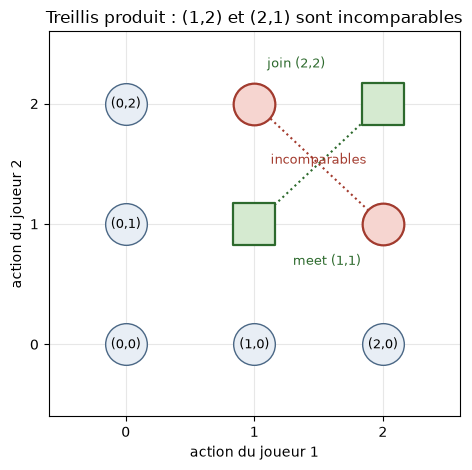

In [3]:
fig, ax = plt.subplots(figsize=(4.8, 4.8))
for a in range(3):
    for b in range(3):
        ax.scatter([a], [b], s=900, color="#e8eef5", edgecolor="#4a6785", zorder=2)
        ax.text(a, b, f"({a},{b})", ha="center", va="center", fontsize=9, zorder=3)

x, y = (1, 2), (2, 1)
lo, hi = meet(x, y), join(x, y)
ax.scatter([x[0], y[0]], [x[1], y[1]], s=900, color="#f6d5d0",
           edgecolor="#a33b2e", linewidth=1.6, zorder=4)
ax.scatter([lo[0], hi[0]], [lo[1], hi[1]], s=900, marker="s",
           color="#d5ead0", edgecolor="#2d6a2d", linewidth=1.6, zorder=4)
ax.annotate("meet (1,1)", xy=lo, xytext=(lo[0] + 0.30, lo[1] - 0.34), fontsize=9,
            color="#2d6a2d")
ax.annotate("join (2,2)", xy=hi, xytext=(hi[0] - 0.90, hi[1] + 0.30), fontsize=9,
            color="#2d6a2d")
ax.annotate("incomparables", xy=(1.5, 1.5), xytext=(1.5, 1.5), fontsize=9,
            ha="center", color="#a33b2e")
ax.plot([1, 2], [2, 1], linestyle=":", color="#a33b2e", zorder=1)
ax.plot([1, 2], [1, 2], linestyle=":", color="#2d6a2d", zorder=1)

ax.set_xlabel("action du joueur 1")
ax.set_ylabel("action du joueur 2")
ax.set_title("Treillis produit : (1,2) et (2,1) sont incomparables")
ax.set_xlim(-0.6, 2.6)
ax.set_ylim(-0.6, 2.6)
ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interprétation : le meet et le join existent toujours, l'ordre total non

La figure rend visible une propriété que le vocabulaire courant masque : dans un
produit de chaînes, **deux éléments incomparables ont néanmoins un meet et un
join**, tous deux dans l'ensemble.

| Paire | Incomparable ? | Meet | Join |
|-------|----------------|------|------|
| $(1,2)$ et $(2,1)$ | oui | $(1,1)$ | $(2,2)$ |
| $(0,0)$ et $(2,2)$ | non (chaîne) | $(0,0)$ | $(2,2)$ |
| $(1,2)$ et $(1,2)$ | non (égalité) | $(1,2)$ | $(1,2)$ |

C'est la définition même d'un treillis : **toute** paire possède un meet et un
join. Un ensemble simplement trié serait un cas particulier (une chaîne), et le
théorème de la section 3 y serait vide de contenu.

> **Pourquoi cela compte pour les équilibria.** Le théorème de Topkis affirme que
> l'ensemble des équilibria purs d'un jeu supermodulaire est lui-même un treillis.
> Ce n'est pas une propriété automatique de tout ensemble d'équilibria : un jeu
> sans complémentarité peut avoir des équilibria disperses, sans meet ni join
> communs. La section 3 le vérifie sur un exemple concret.

## 2. Compléments et substituts stratégiques

### 2.1 Définition par la meilleure réponse

La supermodularité se lit sur les gains ; elle se **voit** sur la meilleure
réponse. Notons $BR_i(a_{-i})$ l'ensemble des actions de $i$ qui maximisent son
gain contre le profil $a_{-i}$.

| Structure | Condition sur les gains | Comportement de la meilleure réponse |
|-----------|-------------------------|--------------------------------------|
| **Compléments stratégiques** | différences croissantes en $(a_i, a_{-i})$ | $BR_i$ **croissante** : quand l'adversaire joue plus haut, je joue plus haut |
| **Substituts stratégiques** | différences décroissantes | $BR_i$ **décroissante** : quand l'adversaire joue plus haut, je joue plus bas |

Pour comparer deux ensembles de meilleures réponses, on utilise l'**ordre fort**
(de Veinott) : $S \le S'$ si, pour tout $s \in S$ et tout $s' \in S'$, on a
$\min(s,s') \in S$ et $\max(s,s') \in S'$. Sur une chaîne finie, cela se lit
simplement : $\max(S) \le \min(S')$.

> **Pourquoi l'ordre fort et pas l'inclusion ?** Une correspondance de meilleure
> réponse peut être multivaluée. L'ordre fort est la bonne notion pour dire
> << la réponse monte >> sans exiger que les ensembles grandissent ou rétrécissent.

### 2.2 Le jeu d'adoption avec externalité de réseau

Deux joueurs choisissent un standard : $A$ (ancien) ou $B$ (moderne).

- Jouer $A$ rapporte toujours $0$.
- Jouer $B$ contre $A$ rapporte $v - c$ (la valeur propre du moderne, moins son
  coût d'adoption).
- Jouer $B$ contre $B$ rapporte $v + n - c$ : s'ajoute l'**externalité de
  réseau** $n > 0$, qui n'existe que si les deux joueurs sont sur $B$.

Le terme $n \cdot \mathbf{1}[a_{-i} = B]$ crée exactement des différences
croissantes : la valeur marginale de choisir $B$ augmente quand l'autre choisit
$B$. C'est le prototype des compléments stratégiques.

In [4]:
def best_responses(U: np.ndarray, opponent_action: int) -> Tuple[int, ...]:
    """Toutes les actions qui maximisent le gain contre opponent_action."""
    column = U[:, opponent_action]
    return tuple(int(a) for a in np.flatnonzero(column >= column.max() - 1e-12))


def br_correspondence(U: np.ndarray) -> List[Tuple[int, ...]]:
    """Correspondance de meilleure reponse, pour chaque action adverse."""
    return [best_responses(U, b) for b in range(U.shape[1])]


def strong_set_leq(S: Sequence[int], S2: Sequence[int]) -> bool:
    """Ordre fort sur des sous-ensembles finis d'une chaine."""
    for s in S:
        for s2 in S2:
            if min(s, s2) not in S or max(s, s2) not in S2:
                return False
    return True


def br_is_increasing(brs: Sequence[Tuple[int, ...]]) -> bool:
    return all(strong_set_leq(brs[b], brs[b + 1]) for b in range(len(brs) - 1))


V_BASE, N_NETWORK, C_ADOPT = 1.0, 1.0, 0.5
ADOPTION = NormalFormGame(
    np.array([[0.0, 0.0],
              [V_BASE - C_ADOPT, V_BASE + N_NETWORK - C_ADOPT]]),
    np.array([[0.0, V_BASE - C_ADOPT],
              [0.0, V_BASE + N_NETWORK - C_ADOPT]]),
    row_labels=["A (ancien)", "B (moderne)"],
    col_labels=["A (ancien)", "B (moderne)"],
    name="Adoption avec externalite de reseau",
)
ADOPTION.display()

for label, U in [("Adoption (complements)", ADOPTION.A),
                 ("Cournot (substituts)", U_COURNOT)]:
    brs = br_correspondence(U)
    print(f"{label}")
    print(f"  BR(b), pour b = 0..{len(brs) - 1} : {brs}")
    print(f"  BR croissante (ordre fort)      : {br_is_increasing(brs)}")
    print(f"  BR decroissante (ordre fort)    : {br_is_increasing(list(reversed(brs)))}")
    print()

print("Les deux jeux se separent nettement :")
print("  - adoption : la meilleure reponse monte avec l'action de l'adversaire ;")
print("  - Cournot  : elle descend (chaque unite adverse retire de la rentabilite).")


Adoption avec externalite de reseau
            A (ancien)   B (moderne)
------------------------------------
A (ancien)  ( 0.0, 0.0)  ( 0.0, 0.5)  
B (moderne)  ( 0.5, 0.0)  ( 1.5, 1.5)  
Adoption (complements)
  BR(b), pour b = 0..1 : [(1,), (1,)]
  BR croissante (ordre fort)      : True
  BR decroissante (ordre fort)    : True

Cournot (substituts)
  BR(b), pour b = 0..9 : [(5,), (4, 5), (4,), (3, 4), (3,), (2, 3), (2,), (1, 2), (1,), (0, 1)]
  BR croissante (ordre fort)      : False
  BR decroissante (ordre fort)    : True

Les deux jeux se separent nettement :
  - adoption : la meilleure reponse monte avec l'action de l'adversaire ;
  - Cournot  : elle descend (chaque unite adverse retire de la rentabilite).


### Interprétation : la monotonie de la meilleure réponse se lit dans la sortie

| Jeu | Correspondance de meilleure réponse | Verdict |
|-----|-------------------------------------|---------|
| Adoption | $BR(A) = \{B\}$, $BR(B) = \{B\}$ | croissante -> **compléments** |
| Cournot | $BR(0) = \{5\}$, $BR(1) = \{4,5\}$, $BR(2) = \{4\}$, ... | décroissante -> **substituts** |

Dans le jeu d'adoption, $B$ est une meilleure réponse **contre les deux** actions
adverses aux paramètres choisis ($v = 1$, $n = 1$, $c = 0.5$). La correspondance
est constante, donc croissante : c'est le cas le plus simple de compléments.

Dans Cournot, la meilleure réponse glisse vers le bas quand l'adversaire produit
davantage. La relation n'est pas seulement décroissante en moyenne : elle l'est
**au sens fort**, ce que le test vérifie paire par paire.

> **Cohérence avec la section 1.** Les verdicts de `br_is_increasing` et de
> `is_increasing_differences` coïncident sur les deux jeux. Ce n'est pas une
> coïncidence : dans un jeu à deux joueurs et actions totalement ordonnées, les
> deux propriétés sont équivalentes. La section 3 utilise la version << gains >>,
> qui est celle du théorème d'existence.

## 3. Le treillis des équilibria purs

### 3.1 Le théorème

On dit qu'un jeu est **supermodulaire** si, pour chaque joueur $i$, le gain
$u_i(a_i, a_{-i})$ est supermodulaire en $(a_i, a_{-i})$ sur le treillis produit
des profils.

**Théorème (Topkis 1978 ; Milgrom et Roberts 1990 ; Vives 1990 ; Zhou 1994).**
Si un jeu fini est supermodulaire, alors l'ensemble de ses équilibria de Nash
**purs** est :

1. **non vide** ;
2. un **treillis complet** pour l'ordre composante par composante ;
3. en particulier, il possède un **plus petit** et un **plus grand** élément.

Le point 1 est le plus surprenant : la supermodularité suffit à garantir
l'existence d'un équilibre **pur**, sans recourir aux stratégies mixtes ni au
théorème de point fixe de [4c](GameTheory-04c-NashExistence-Python.ipynb). Le
point 2 est plus fin : ce n'est pas seulement << il existe un équilibre >>, c'est
<< l'ensemble des équilibria a une forme >>.

### 3.2 Un jeu où le treillis est visible

Reprenons le jeu de standard de la section 1 :

$$u_1(a, b) = \begin{cases} 2 & \text{si } a \ge 1 \text{ et } b \ge 1 \\ 0 & \text{sinon} \end{cases}$$

Le profil $(0,0)$ est un équilibre : aucun joueur ne gagne à moderniser **seul**.
C'est le **verrouillage** (*lock-in*). Mais dès que l'autre est sur une variante
moderne, toutes les variantes modernes se valent : le carré $\{1,2\} \times
\{1,2\}$ tout entier est un ensemble d'équilibria. L'ensemble des équilibria est
donc $\{(0,0)\} \cup \{1,2\}^2$ — cinq profils, dont deux incomparables.

In [5]:
def leq(x: Tuple[int, int], y: Tuple[int, int]) -> bool:
    return all(a <= b for a, b in zip(x, y))


def lattice_report(U1: np.ndarray, U2: np.ndarray, name: str) -> Dict[str, object]:
    """Enumere les equilibria purs et verifie la cloture du treillis."""
    game = NormalFormGame(U1, U2, name=name)
    ne = find_pure_nash(game)
    ne_set = set(ne)
    failures = []
    for x, y in itertools.combinations(ne, 2):
        lo, hi = meet(x, y), join(x, y)
        if lo not in ne_set or hi not in ne_set:
            failures.append((x, y, lo, hi))
    smallest = (min(a for a, _ in ne), min(b for _, b in ne))
    largest = (max(a for a, _ in ne), max(b for _, b in ne))
    return {"game": game, "ne": ne, "ne_set": ne_set, "failures": failures,
            "smallest": smallest, "largest": largest}


REPORT = lattice_report(U_THRESHOLD, U_THRESHOLD,
                        "Standard ancien vs moderne (jeu symetrique)")
REPORT["game"].display()

print(f"Equilibria purs        : {REPORT['ne']}")
print(f"Nombre d'equilibria    : {len(REPORT['ne'])}")
print(f"Plus petit equilibre   : {REPORT['smallest']} "
      f"(present : {REPORT['smallest'] in REPORT['ne_set']})")
print(f"Plus grand equilibre   : {REPORT['largest']} "
      f"(present : {REPORT['largest'] in REPORT['ne_set']})")
print(f"Paires non closes      : "
      f"{REPORT['failures'] if REPORT['failures'] else 'aucune'}")

print()
print("Verification de la paire incomparable (1,2) et (2,1) :")
x, y = (1, 2), (2, 1)
print(f"  {x} ^ {y} = {meet(x, y)}  -> equilibre : {meet(x, y) in REPORT['ne_set']}")
print(f"  {x} v {y} = {join(x, y)}  -> equilibre : {join(x, y) in REPORT['ne_set']}")


Standard ancien vs moderne (jeu symetrique)
                    C0            C1            C2
--------------------------------------------------
      R0  ( 0.0, 0.0)  ( 0.0, 0.0)  ( 0.0, 0.0)  
      R1  ( 0.0, 0.0)  ( 2.0, 2.0)  ( 2.0, 2.0)  
      R2  ( 0.0, 0.0)  ( 2.0, 2.0)  ( 2.0, 2.0)  
Equilibria purs        : [(0, 0), (1, 1), (1, 2), (2, 1), (2, 2)]
Nombre d'equilibria    : 5
Plus petit equilibre   : (0, 0) (present : True)
Plus grand equilibre   : (2, 2) (present : True)
Paires non closes      : aucune

Verification de la paire incomparable (1,2) et (2,1) :
  (1, 2) ^ (2, 1) = (1, 1)  -> equilibre : True
  (1, 2) v (2, 1) = (2, 2)  -> equilibre : True


### Interprétation : le treillis est vérifie, pas seulement annonce

La sortie donne les cinq équilibria purs et la clôture de toutes leurs paires :

| Propriété | Valeur observée |
|-----------|-----------------|
| Équilibria | $(0,0)$, $(1,1)$, $(1,2)$, $(2,1)$, $(2,2)$ |
| Plus petit | $(0,0)$ — présent dans l'ensemble |
| Plus grand | $(2,2)$ — présent dans l'ensemble |
| Paires non closes | **aucune** |

**Le point décisif est la paire incomparable.** $(1,2)$ et $(2,1)$ ne sont
ordonnes ni l'un ni l'autre ; pourtant leur meet $(1,1)$ et leur join $(2,2)$
sont **tous deux** des équilibria. C'est cela, être un treillis : la clôture sous
$\wedge$ et $\vee$, pas seulement l'existence d'un maximum et d'un minimum.

**Lecture économique.** Le plus petit équilibre $(0,0)$ est le **verrouillage sur
l'ancien standard** ; le plus grand $(2,2)$ est la **coordination sur le moderne**.
Entre les deux, tout le carré moderne est indifférent — les joueurs n'ont aucune
raison de se coordonner sur une variante plutot que l'autre, et le treillis
enregistre cette indifférence.

> **Ou sont les équilibria mixtes ?** Le théorème porte sur les équilibria
> **purs**. Un jeu supermodulaire peut aussi avoir des équilibria mixtes, mais
> l'énumération ci-dessus, comme `find_pure_nash`, ne regarde que les profils
> purs. Le résultat de treillis est précisément intéressant parce qu'il garantit
> l'existence en pur.

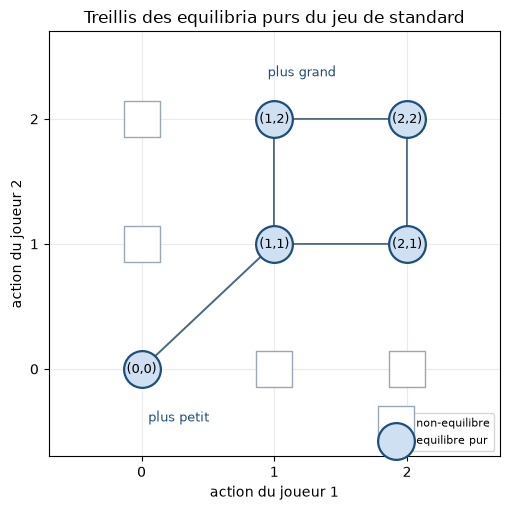

In [6]:
def hasse_edges(ne_set) -> List[Tuple[Tuple[int, int], Tuple[int, int]]]:
    """Couples (x, y) d'equilibria comparables sans element intermediaire."""
    edges = []
    for x in ne_set:
        for y in ne_set:
            if x == y or not leq(x, y):
                continue
            between = [z for z in ne_set
                       if z != x and z != y and leq(x, z) and leq(z, y)]
            if not between:
                edges.append((x, y))
    return edges


fig, ax = plt.subplots(figsize=(5.2, 5.2))
all_points = grid_points(3, 3)
ne_points = sorted(REPORT["ne_set"])
non_ne = [p for p in all_points if p not in REPORT["ne_set"]]

for a, b in hasse_edges(REPORT["ne_set"]):
    ax.plot([a[0], b[0]], [a[1], b[1]], color="#4a6785", linewidth=1.4, zorder=1)

ax.scatter([p[0] for p in non_ne], [p[1] for p in non_ne], s=700, marker="s",
           facecolor="white", edgecolor="#9aa7b4", zorder=2, label="non-equilibre")
ax.scatter([p[0] for p in ne_points], [p[1] for p in ne_points], s=700,
           color="#cfe0f2", edgecolor="#1f4e79", linewidth=1.6, zorder=3,
           label="equilibre pur")
for a, b in ne_points:
    ax.text(a, b, f"({a},{b})", ha="center", va="center", fontsize=9, zorder=4)

lo_p, hi_p = REPORT["smallest"], REPORT["largest"]
ax.annotate("plus petit", xy=lo_p, xytext=(lo_p[0] + 0.05, lo_p[1] - 0.42),
            fontsize=9, color="#1f4e79")
ax.annotate("plus grand", xy=hi_p, xytext=(hi_p[0] - 1.05, hi_p[1] + 0.34),
            fontsize=9, color="#1f4e79")

ax.set_xlabel("action du joueur 1")
ax.set_ylabel("action du joueur 2")
ax.set_title("Treillis des equilibria purs du jeu de standard")
ax.set_xlim(-0.7, 2.7)
ax.set_ylim(-0.7, 2.7)
ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.grid(True, alpha=0.25)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### Interprétation : lire le treillis comme un diagramme de Hasse

La figure trace les **couples couvrants** de l'ensemble des équilibria : une
arête relie deux équilibria comparables quand aucun autre équilibre ne s'intercale
entre eux. C'est la lecture standard d'un treillis fini.

| Élément | Rôle |
|---------|------|
| $(0,0)$ | plus petit équilibre : verrouillage sur l'ancien standard |
| $(2,2)$ | plus grand équilibre : coordination sur la variante haute |
| $(1,1)$ | meet de $(1,2)$ et $(2,1)$ |
| $(1,2)$, $(2,1)$ | incomparables, tous deux équilibria |

Les points hors de l'ensemble (cases vides) sont des profils qui ne sont **pas**
des équilibria : par exemple $(0,1)$, où le joueur 1 gagnerait à passer de $0$ à $1$ puisque le joueur 2 est déjà sur une variante moderne.

> **Un treillis n'est pas un arbre.** Le diagramme contient un carré : les deux
> chemins de $(1,1)$ à $(2,2)$ — par $(1,2)$ ou par $(2,1)$ — sont tous deux
> valides. C'est la signature visuelle de l'ordre partiel, et la raison pour
> laquelle << le plus grand >> et << le plus petit >> sont bien définis même
> quand il existe plusieurs éléments maximaux locaux.

## 4. Comparaison monotone des équilibria

### 4.1 Le second théorème

Les équilibria d'un jeu dépendent de paramètres : coût d'adoption, taxe,
productivité, subvention. La question naturelle est : **que fait un changement de paramètre à l'ensemble des équilibria ?**

**Théorème (comparaison monotone de Topkis).** Soit $\theta$ un paramètre tel que
chaque gain $u_i(a_i, a_{-i}, \theta)$ ait des différences croissantes en
$(a_i, \theta)$, en plus des différences croissantes en $(a_i, a_{-i})$. Alors le
plus petit et le plus grand équilibre pur sont **non décroissants** en $\theta$.

Autrement dit : si le paramètre rend l'action haute relativement plus attractive,
les équilibres extrêmes ne peuvent que **monter**. Ils peuvent rester sur place,
mais jamais descendre — et c'est tout ce que le théorème promet.

> **Ce que le théorème ne dit pas.** Il ne dit rien de la continuité : les
> équilibres extrêmes peuvent **sauter** d'un niveau à l'autre quand le paramètre
> franchit un seuil. Une fonction non décroissante peut avoir des marches. La
> section 4.2 en montre un exemple.

### 4.2 Une subvention au standard moderne

Reprenons le jeu d'adoption et interprétons $\theta$ comme la **valeur du
standard moderne** (subvention, gain de productivité). Le coût d'adoption de base
est $c_0 = 2$ et l'externalité de réseau vaut $n = 1$ :

- $u_1(A, \cdot) = 0$ ;
- $u_1(B, A) = \theta - c_0$ ;
- $u_1(B, B) = \theta + n - c_0$.

Le paramètre $\theta$ entre dans le gain de $B$ seulement : la différence
$u_1(B, \cdot) - u_1(A, \cdot)$ croit avec $\theta$, donc les différences
croissantes en $(a_1, \theta)$ sont satisfaites.

In [7]:
C_ADOPT_BASE = 2.0


def adoption_game(theta: float) -> NormalFormGame:
    """Jeu d'adoption parametre par la valeur theta du standard moderne."""
    u_ba = theta - C_ADOPT_BASE
    u_bb = theta + N_NETWORK - C_ADOPT_BASE
    A = np.array([[0.0, 0.0], [u_ba, u_bb]])
    B = np.array([[0.0, u_ba], [0.0, u_bb]])
    return NormalFormGame(A, B, row_labels=["A", "B"],
                          col_labels=["A", "B"])


def extremes(U1: np.ndarray, U2: np.ndarray):
    """Plus petit et plus grand equilibre pur, et la liste complete."""
    ne = find_pure_nash(NormalFormGame(U1, U2))
    if not ne:
        return None, None, ne
    return ((min(a for a, _ in ne), min(b for _, b in ne)),
            (max(a for a, _ in ne), max(b for _, b in ne)),
            ne)


thetas = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
print(f"{'theta':>6} | {'equilibria purs':<22} | {'plus petit':^11} | {'plus grand':^11}")
print("-" * 62)
previous = None
for theta in thetas:
    g = adoption_game(theta)
    lo, hi, ne = extremes(g.A, g.B)
    print(f"{theta:>6.2f} | {str(ne):<22} | {str(lo):^11} | {str(hi):^11}")
    if previous is not None:
        assert leq(previous[0], lo) and leq(previous[1], hi), \
            "violation de la monotonie"
    previous = (lo, hi)

print()
print("Les deux equilibres extremes sont non decroissants en theta.")
print("La bande theta dans [1, 2] est une zone de coexistence :")
print("les deux equilibres existent simultanement (effet d'hysteresis).")

 theta | equilibria purs        | plus petit  | plus grand 
--------------------------------------------------------------
  0.00 | [(0, 0)]               |   (0, 0)    |   (0, 0)   
  0.50 | [(0, 0)]               |   (0, 0)    |   (0, 0)   
  1.00 | [(0, 0), (1, 1)]       |   (0, 0)    |   (1, 1)   
  1.50 | [(0, 0), (1, 1)]       |   (0, 0)    |   (1, 1)   
  2.00 | [(0, 0), (1, 1)]       |   (0, 0)    |   (1, 1)   
  2.50 | [(1, 1)]               |   (1, 1)    |   (1, 1)   
  3.00 | [(1, 1)]               |   (1, 1)    |   (1, 1)   

Les deux equilibres extremes sont non decroissants en theta.
La bande theta dans [1, 2] est une zone de coexistence :
les deux equilibres existent simultanement (effet d'hysteresis).


### Interprétation : une bande de coexistence, pas une bascule nette

Le tableau montre trois régimes :

| Plage de $\theta$ | Équilibria | Plus petit | Plus grand |
|-------------------|------------|------------|------------|
| $\theta < 1$ | $\{(A,A)\}$ | $A$ | $A$ |
| $1 \le \theta \le 2$ | $\{(A,A), (B,B)\}$ | $A$ | $B$ |
| $\theta > 2$ | $\{(B,B)\}$ | $B$ | $B$ |

**Pourquoi une bande ?** Entre $\theta = 1$ et $\theta = 2$, chacun des deux
profils est un équilibre :

- $(A,A)$ tient parce que moderniser seul ne vaut pas le coût : $u_1(B,A) =
  \theta - 2 \le 0$ ;
- $(B,B)$ tient parce que la coordination rend le moderne rentable : $u_1(B,B) =
  \theta - 1 \ge 0$.

La largeur de la bande est exactement l'externalité de réseau $n = 1$. Plus le
réseau est fort, plus la **coexistence** est large — et plus le système peut
rester bloqué sur l'ancien standard alors que le nouveau serait collectivement
meilleur.

> **Deux lecteurs du même théorème.** Le plus grand équilibre bascule à
> $\theta = 1$ ; le plus petit à $\theta = 2$. Les deux sont non décroissants,
> conformément au théorème, mais ils ne basculent **pas au même seuil** : c'est
> précisément la coexistence qui distingue les deux fonctions. Une politique qui
> ne regarde que l'équilibre le plus favorable surestime la facilité du
> basculement.

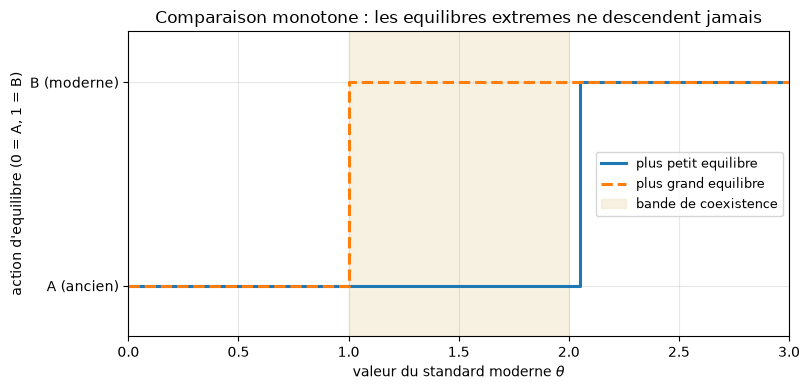

In [8]:
theta_grid = np.linspace(0.0, 3.0, 61)
small, large = [], []
for t in theta_grid:
    g = adoption_game(float(t))
    lo, hi, _ = extremes(g.A, g.B)
    small.append(lo[0] if lo is not None else np.nan)
    large.append(hi[0] if hi is not None else np.nan)

fig, ax = plt.subplots(figsize=(8.2, 4.0))
ax.step(theta_grid, small, where="post", linewidth=2.2,
        label="plus petit equilibre")
ax.step(theta_grid, large, where="post", linewidth=2.2, linestyle="--",
        label="plus grand equilibre")
ax.axvspan(1.0, 2.0, color="#f2e6c9", alpha=0.55,
           label="bande de coexistence")
ax.set_xlabel(r"valeur du standard moderne $\theta$")
ax.set_ylabel("action d'equilibre (0 = A, 1 = B)")
ax.set_title("Comparaison monotone : les equilibres extremes ne descendent jamais")
ax.set_yticks([0, 1])
ax.set_yticklabels(["A (ancien)", "B (moderne)"])
ax.set_xlim(0, 3)
ax.set_ylim(-0.25, 1.25)
ax.grid(True, alpha=0.3)
ax.legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.show()

### Interprétation : des marches, pas une pente

La figure trace deux fonctions **en escalier** du paramètre $\theta$ :

| Fonction | Seuil de bascule | Lecture |
|----------|------------------|---------|
| Plus petit équilibre | $\theta = 2$ | en dessous, le verrouillage $(A,A)$ survit |
| Plus grand équilibre | $\theta = 1$ | dès que le moderne est rentable sous coordination, $(B,B)$ apparaît |

Les deux courbes sont non décroissantes : elles montent ou restent plates, jamais
l'inverse. C'est exactement l'énoncé du théorème — et l'absence de continuité
n'est pas une violation : le théorème porte sur la **monotonie**, pas sur la
continuité.

> **Test de compréhension.** Si l'on supprimait l'externalité de réseau ($n = 0$),
> que deviendrait la bande de coexistence ? Réponse attendue : elle se réduit à un
> point ($\theta = c_0$), les deux seuils se confondent, et la bascule redevient
> nette. L'exercice 4 fait varier ce paramètre.

## 5. Ce que ce treillis n'est pas : les matchings stables

### 5.1 Deux treillis, deux ordres

La série contient déjà un treillis, mais c'est un **autre objet**. Le module Lean
`game_theory_lean/StableMarriage/Lattice.lean` traite le treillis de **Roth** :
les matchings stables d'un marché à deux côtés.

| | Treillis des équilibria (ce carnet) | Treillis des matchings stables |
|---|---|---|
| Objets | profils d'actions $(a_1, \dots, a_n)$ | appariements entre deux côtés |
| Ordre | **composante par composante** : $a \le a'$ si $a_i \le a'_i$ pour tout $i$ | **par préférences** : $M \le M'$ si chaque agent d'un côté préfère son partenaire dans $M'$ |
| Origine de la structure | la **forme des gains** (complémentarité) | les **préférences** des agents |
| Théorème | Topkis, Milgrom-Roberts, Zhou | Gale-Shapley, Roth |
| Extrêmes | plus petit / plus grand équilibre | optimal pour un côté / optimal pour l'autre |

**La différence décisive** : dans le treillis des équilibria, l'ordre est
**extrinsèque** — il vient de l'ordre numérique des actions, pas des gains. Dans
le treillis des matchings, l'ordre est **intrinsèque** — il est **défini** par
les préférences : il n'existe pas d'ordre << naturel >> sur les appariements.

### 5.2 Vérifier la différence sur une instance

Prenons deux hommes et deux femmes, avec des préférences croisées :

- $m_1 : w_1 \succ w_2$ et $m_2 : w_2 \succ w_1$ ;
- $w_1 : m_2 \succ m_1$ et $w_2 : m_1 \succ m_2$.

On énumère les deux appariements possibles, on teste la stabilité de chacun, et on
compare les deux issues de Gale-Shapley (hommes proposants, femmes proposantes).

In [9]:
MEN_PREFS = {"m1": ["w1", "w2"], "m2": ["w2", "w1"]}
WOMEN_PREFS = {"w1": ["m2", "m1"], "w2": ["m1", "m2"]}


def is_stable(matching: Dict[str, str],
              proposer_prefs: Dict[str, List[str]],
              receiver_prefs: Dict[str, List[str]]) -> bool:
    """Vrai s'il n'existe aucune paire bloquante."""
    inverse = {r: p for p, r in matching.items()}
    for p, prefs in proposer_prefs.items():
        current = matching[p]
        for r in prefs[:prefs.index(current)]:
            other = inverse[r]
            if receiver_prefs[r].index(p) < receiver_prefs[r].index(other):
                return False
    return True


all_matchings = [dict(zip(["m1", "m2"], perm))
                 for perm in itertools.permutations(["w1", "w2"])]
stable_matchings = [m for m in all_matchings
                    if is_stable(m, MEN_PREFS, WOMEN_PREFS)]

men_optimal = gale_shapley(MEN_PREFS, WOMEN_PREFS)
women_optimal = {m: w for w, m in gale_shapley(WOMEN_PREFS, MEN_PREFS).items()}
women_optimal = {m: women_optimal[m] for m in sorted(women_optimal)}

print("Tous les appariements et leur stabilite")
print("=" * 58)
for m in all_matchings:
    verdict = "stable" if m in stable_matchings else "instable (paire bloquante)"
    print(f"  {m}  ->  {verdict}")

print()
print(f"Nombre de matchings stables : {len(stable_matchings)}")
print(f"Gale-Shapley, hommes proposants : {men_optimal}")
print(f"Gale-Shapley, femmes proposantes : {women_optimal}")
print()
print("Ordre du treillis de Roth -- par PREFERENCE, pas par composante :")
print("  cote hommes  :", men_optimal, ">=", women_optimal,
      "(chaque homme prefere son partenaire dans le premier)")
print("  cote femmes  :", women_optimal, ">=", men_optimal,
      "(chaque femme prefere son partenaire dans le second)")

Tous les appariements et leur stabilite
  {'m1': 'w1', 'm2': 'w2'}  ->  stable
  {'m1': 'w2', 'm2': 'w1'}  ->  stable

Nombre de matchings stables : 2
Gale-Shapley, hommes proposants : {'m1': 'w1', 'm2': 'w2'}
Gale-Shapley, femmes proposantes : {'m1': 'w2', 'm2': 'w1'}

Ordre du treillis de Roth -- par PREFERENCE, pas par composante :
  cote hommes  : {'m1': 'w1', 'm2': 'w2'} >= {'m1': 'w2', 'm2': 'w1'} (chaque homme prefere son partenaire dans le premier)
  cote femmes  : {'m1': 'w2', 'm2': 'w1'} >= {'m1': 'w1', 'm2': 'w2'} (chaque femme prefere son partenaire dans le second)


### Interprétation : deux treillis, deux natures d'ordre

La sortie confirme qu'il y a exactement **deux** matchings stables, et qu'ils
coïncident avec les deux issues de Gale-Shapley :

| Matching | Hommes proposants | Femmes proposantes |
|----------|-------------------|--------------------|
| $m_1 \leftrightarrow w_1$, $m_2 \leftrightarrow w_2$ | oui (optimal pour les hommes) | non |
| $m_1 \leftrightarrow w_2$, $m_2 \leftrightarrow w_1$ | non | oui (optimal pour les femmes) |

**Le contraste avec la section 3 est net :**

- Dans le treillis des équilibria, comparer $(1,1)$ et $(2,2)$ ne demande aucune
  préférence : $1 \le 2$ et $1 \le 2$, donc $(1,1) \le (2,2)$. L'ordre existe
  **avant** les agents.
- Dans le treillis des matchings, comparer les deux matchings stables **exige de
  choisir un côté**. Le premier est plus grand pour les hommes, le second pour les
  femmes ; il n'y a pas d'ordre qui les classe tous les deux de la même façon.

> **Pourquoi cette section existe.** Le mot << treillis >> apparaît déjà dans la
> série, mais il désignait jusqu'ici le treillis de Roth. Sans cette distinction,
> un lecteur pourrait croire que les deux résultats sont le même théorème applique
> deux fois. Ce sont deux théorèmes distincts, sur deux structures distinctes,
> avec deux notions d'ordre distinctes.

## 6. Exercices

Les quatre exercices suivants réutilisent les fonctions des sections précédentes.
Aucun ne demande de code nouveau : il s'agit de **classifier**, de **vérifier** et
d'**interpréter**. Les cellules s'exécutent telles quelles et affichent
<< Exercice à compléter >> tant que les fonctions ne sont pas remplies.

### Exercice 1 — Classifier un jeu par ses gains

Soit le jeu bi-matrice ci-dessous, où chaque joueur veut **différer** de l'autre
et où la coordonnée $(2,2)$ est un refuge de faible valeur :

$$U = \begin{pmatrix} 0 & 2 & 0 \\ 2 & 0 & 0 \\ 0 & 0 & 1 \end{pmatrix}$$

1. Implémenter `classify_supermodularity` : appeler `is_supermodular` et
   `is_increasing_differences`, puis renvoyer les deux verdicts et la **première
   violation** rencontrée.
2. Vérifier à la main sur la paire $x = (0,1)$, $y = (1,0)$ que
   $f(x \vee y) + f(x \wedge y) < f(x) + f(y)$.

> **Indice** : `is_supermodular` renvoie un couple `(booleen, violations)`. La
première violation suffit pour le verdict.


In [10]:
U_EX1 = np.array([[0.0, 2.0, 0.0],
                  [2.0, 0.0, 0.0],
                  [0.0, 0.0, 1.0]])


def classify_supermodularity(U: np.ndarray) -> Dict[str, object]:
    """Verdict des deux tests, et premiere violation rencontree."""
    # TODO etudiant : appeler is_supermodular et is_increasing_differences,
    # puis renvoyer un dictionnaire avec les deux verdicts et la premiere
    # violation du test de supermodularite.
    print("Exercice a completer")
    return None


verdict_ex1 = classify_supermodularity(U_EX1)
if verdict_ex1 is not None:
    print(verdict_ex1)

Exercice a completer


### Exercice 2 — Compléments ou substituts ?

Soit le jeu $U = \begin{pmatrix} 0 & 3 \\ 2 & 0 \end{pmatrix}$, où chaque joueur
gagne à faire l'inverse de l'autre.

1. Calculer à la main $BR(0)$ et $BR(1)$ pour le joueur ligne.
2. Implémenter `classify_complements` : renvoyer `"complements"` si la
   correspondance de meilleure réponse est croissante au sens fort,
   `"substituts"` si elle est décroissante, `"indetermine"` sinon.
3. Comparer le verdict avec celui de `is_increasing_differences(U)`.

> **Indice** : `br_correspondence` et `br_is_increasing` sont déjà écrites en
section 2. Pour le sens décroissant, tester la correspondance **renversée**
(`brs[::-1]`) avec la même fonction.


In [11]:
U_EX2 = np.array([[0.0, 3.0],
                  [2.0, 0.0]])


def classify_complements(U: np.ndarray) -> str:
    """'complements', 'substituts' ou 'indetermine'."""
    # TODO etudiant : construire br_correspondence(U) puis tester la
    # croissance (br_is_increasing) et la decroissance (la meme fonction
    # appliquee a la correspondance renversee).
    print("Exercice a completer")
    return None


verdict_ex2 = classify_complements(U_EX2)
if verdict_ex2 is not None:
    print(f"Verdict : {verdict_ex2}")

Exercice a completer


### Exercice 3 — Vérifier la clôture d'un treillis

Soit le jeu symétrique de matrice :

$$U = \begin{pmatrix}
0 & 0 & 0 & 0 \\
0 & 2 & 2 & 2 \\
0 & 2 & 2 & 2 \\
0 & 2 & 3 & 4
\end{pmatrix}$$

1. Implémenter `ne_lattice_check` en reutilisant `lattice_report(U, U, nom)`.
2. Renvoyer les équilibria purs, le nombre de paires non closes, le plus petit et
   le plus grand équilibre.
3. Interpréter : l'ensemble obtenu est-il un treillis ? Combien d'éléments
   contient-il, et lesquels ?

> **Indice** : la fonction `lattice_report` de la section 3 renvoie déjà toutes ces
informations dans un dictionnaire — l'exercice consiste à les extraire et à les présenter, pas à recalculer la clôture.


In [12]:
U_EX3 = np.array([[0.0, 0.0, 0.0, 0.0],
                  [0.0, 2.0, 2.0, 2.0],
                  [0.0, 2.0, 2.0, 2.0],
                  [0.0, 2.0, 3.0, 4.0]])


def ne_lattice_check(U: np.ndarray) -> Dict[str, object]:
    """Equilibria, paires non closes, plus petit et plus grand."""
    # TODO etudiant : appeler lattice_report(U, U, "Exercice 3") et renvoyer
    # un dictionnaire resume (ne, failures, smallest, largest).
    print("Exercice a completer")
    return None


bilan_ex3 = ne_lattice_check(U_EX3)
if bilan_ex3 is not None:
    print(bilan_ex3)

Exercice a completer


### Exercice 4 — Comparaison monotone avec une autre externalité

On reprend le jeu d'adoption, mais avec un coût d'adoption $c_0 = 1$ et une
externalité de réseau $n = 1.5$ :

- $u_1(A, \cdot) = 0$ ;
- $u_1(B, A) = t - 1$ ;
- $u_1(B, B) = t + 0.5$.

1. Implémenter `check_monotone_statics` : pour chaque valeur de $t$ fournie,
   calculer les équilibres extrêmes, vérifier qu'**aucun ne descend** par rapport à la valeur précédente, et identifier les valeurs de $t$ ou les deux
   équilibres coexistent.
2. En déduire la **bande de coexistence** et sa largeur.
3. Comparer avec la section 4.2 : la largeur de la bande vaut-elle bien
   l'externalité de réseau $n$ ?

> **Indice** : `extremes` renvoie `(plus petit, plus grand, liste)`. La coexistence
se lit directement sur `len(liste) == 2`.


In [13]:
def adoption_game_ex4(t: float) -> NormalFormGame:
    """Jeu d'adoption avec c0 = 1 et n = 1.5."""
    u_ba, u_bb = t - 1.0, t + 0.5
    A = np.array([[0.0, 0.0], [u_ba, u_bb]])
    B = np.array([[0.0, u_ba], [0.0, u_bb]])
    return NormalFormGame(A, B, row_labels=["A", "B"], col_labels=["A", "B"])


def check_monotone_statics(t_values: Sequence[float]) -> Dict[str, object]:
    """Monotonie des extremes et bande de coexistence."""
    # TODO etudiant : boucler sur t_values, appeler extremes(...), verifier
    # la non-decroissance des deux bornes, et collecter les t ou les deux
    # equilibres coexistent.
    print("Exercice a completer")
    return None


bilan_ex4 = check_monotone_statics([-1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0])
if bilan_ex4 is not None:
    print(bilan_ex4)

Exercice a completer


## Résumé

Ce carnet a remplace la question << **y a-t-il** un équilibre ? >> (carnet 4c) par
la question << **quelle est la forme** de l'ensemble des équilibria ? >>.

| Section | Résultat | Vérification |
|---------|----------|--------------|
| 1 | treillis produit, supermodularité, différences croissantes | tests exhaustifs sur 9 et 100 profils |
| 1 | lemme de Topkis : les deux tests sont équivalents sur une chaîne finie | les deux verdicts concordent sur les deux jeux |
| 2 | compléments = meilleure réponse croissante ; substituts = décroissante | correspondances affichées et testées à l'ordre fort |
| 3 | l'ensemble des équilibria purs d'un jeu supermodulaire est un treillis complet | 5 équilibria, 0 paire non close, meet et join vérifiés |
| 4 | les équilibres extrêmes sont non décroissants en un paramètre | tableau de 7 valeurs + courbes en escalier |
| 5 | le treillis des équilibria n'est pas le treillis des matchings | 2 matchings stables, ordres par des préférences |

**Les trois idées à retenir :**

1. **La complémentarité est une propriété de la forme des gains**, pas du nombre
   d'équilibres. Elle se lit sur une matrice, par différences croissantes.
2. **Un jeu supermodulaire a toujours un équilibre pur**, et son ensemble
   d'équilibria est structure : plus petit, plus grand, clôture sous meet et join.
3. **La comparaison monotone explique l'hystérésis** : quand deux équilibres
   coexistent, le système peut rester bloqué sur le plus petit alors qu'un
   paramètre a déjà franchi le seuil du plus grand.

> **Ce que le carnet ne traite pas.** Les jeux à plus de deux joueurs, les
> actions continues et les extensions infinies demandent des arguments de
> compacité que le cadre fini évite ; les jeux globaux (sélection d'équilibre par
> information incomplète) font l'objet d'un carnet dédié. Le treillis des
> matchings stables est traite dans le module Lean `game_theory_lean/StableMarriage/Lattice.lean`.

### Références académiques

- **Topkis, D.M.** (1978). *Minimizing a Submodular Function on a Lattice*.
  Operations Research 26(2):305-321. — Le théorème de comparaison monotone pour
  les optimiseurs paramètres, fondement des sections 3 et 4.
- **Milgrom, P. et Roberts, J.** (1990). *Rationalizability, Learning, and
  Equilibrium in Games with Strategic Complementarities*. Econometrica
  58(6):1255-1277. — Les compléments stratégiques et le treillis des équilibria.
- **Vives, X.** (1990). *Nash Equilibrium with Strategic Complementarities*.
  Journal of Mathematical Economics 19(3):305-321. — Existence et comparaison
  dans les jeux à compléments.
- **Zhou, L.** (1994). *The Set of Nash Équilibria of a Supermodular Game is a
  Complete Lattice*. Games and Economic Behavior 7(2):295-300. — La clôture
  complete du treillis, vérifiée en section 3.
- **Gale, D. et Shapley, L.S.** (1962). *College Admissions and the Stability of
  Marriage*. American Mathematical Monthly 69(1):9-15. — L'algorithme de
  Gale-Shapley, réutilise en section 5.
- **Roth, A.E. et Sotomayor, M.A.O.** (1990). *Two-Sided Matching: A Study in
  Game-Theoretic Modeling and Analysis*. Cambridge University Press. — Le
  treillis des matchings stables, distingue en section 5.

**Prolongements dans la série :** [4c (existence par point fixe)](GameTheory-04c-NashExistence-Python.ipynb) . [4b (existence en Lean)](GameTheory-04b-Lean-NashExistence-Lean.ipynb)

***

**Navigation** : [<< 4f-Theories-Decision-Predicteur](GameTheory-04f-Theories-Decision-Predicteur-Python.ipynb) | [Index](README.md)

**Autres approfondissements de 04** : [4-NashEquilibrium (track principal)](GameTheory-04-NashEquilibrium-Python.ipynb) · [4b-Lean-NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb) · [4c-NashExistence](GameTheory-04c-NashExistence-Python.ipynb) · [4d-Marchandage-Asymetrique](GameTheory-04d-Marchandage-Asymetrique-Python.ipynb) · [4e-Reflective-Oracles](GameTheory-04e-Reflective-Oracles-Python.ipynb) · [4f-Theories-Decision-Predicteur](GameTheory-04f-Theories-Decision-Predicteur-Python.ipynb)
